In [1]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models, optimizers
from sklearn.metrics import classification_report
import numpy as np

2025-09-03 19:37:13.839721: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1756903033.968314     749 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1756903034.006567     749 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-03 19:37:14.350687: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Config

In [2]:
NUM_CLASSES = 7
BATCH_SIZE = 8
EPOCHS = 50
IMG_SIZE = (224, 224)

SOURCE_DIR = "/mnt/c/KULIAH_S007/DomainAdaptation_Thesis/ISIC2019_merged"   # source labeled
TEST_DIR   = "/mnt/c/KULIAH_S007/DomainAdaptation_Thesis/fitz_selected"     # target labeled (for evaluation)


# Dataset pipeline

In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    SOURCE_DIR,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# Prefetch for performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


Found 25078 files belonging to 7 classes.


I0000 00:00:1756903081.831035     749 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Found 2059 files belonging to 7 classes.


# Build MobileNetV2 baseline

In [4]:
base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Freeze base initially

inputs = layers.Input(shape=(224,224,3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = models.Model(inputs, outputs)

# Compile
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# Fine-tune (optional)

In [5]:
base_model.trainable = True
model.compile(
    optimizer=optimizers.Adam(1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/50


I0000 00:00:1756903099.910862    1093 service.cc:148] XLA service 0x789fcc003660 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1756903099.912072    1093 service.cc:156]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6
2025-09-03 19:38:20.546576: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1756903102.744306    1093 cuda_dnn.cc:529] Loaded cuDNN version 91100
2025-09-03 19:38:31.809816: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng3{k11=2} for conv (f32[8,576,14,14]{3,2,1,0}, u8[0]{0}) custom-call(f32[8,576,14,14]{3,2,1,0}, f32[576,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=576, custom_call_target="__cudnn$convForward", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kN

3133/3135 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5233 - loss: 1.3278

E0000 00:00:1756903294.815184    1091 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756903295.057253    1091 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1756903295.288568    1091 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2025-09-03 19:41:35.505215: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng3{k11=2} for conv (f32[6,960,7,7]{3,2,1,0}, u8[0]{0}) custom-call(f32[6,960,7,7]{3,2,1,0}, f32[960,1,3,3]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, feature_group_count=960, custom_call_target="__cudnn$convForward", backend_config={"cudnn_conv_backend_config":{"activati

3135/3135 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.5234 - loss: 1.3277

2025-09-03 19:41:58.703291: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1193', 8 bytes spill stores, 8 bytes spill loads

2025-09-03 19:41:58.881888: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1193', 356 bytes spill stores, 468 bytes spill loads

2025-09-03 19:42:05.975377: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1193', 8 bytes spill stores, 8 bytes spill loads

2025-09-03 19:42:06.110082: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1193', 188 bytes spill stores, 188 bytes spill loads

E0000 00:00:1756903333.064985    1091 gpu_timer.cc:82] Delay

3135/3135 ━━━━━━━━━━━━━━━━━━━━ 252s 65ms/step - accuracy: 0.5234 - loss: 1.3276 - val_accuracy: 0.1593 - val_loss: 3.0335
Epoch 2/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 173s 55ms/step - accuracy: 0.6617 - loss: 0.9475 - val_accuracy: 0.1598 - val_loss: 3.1245
Epoch 3/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 179s 57ms/step - accuracy: 0.6857 - loss: 0.8690 - val_accuracy: 0.1671 - val_loss: 3.3123
Epoch 4/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 181s 58ms/step - accuracy: 0.7058 - loss: 0.8113 - val_accuracy: 0.1831 - val_loss: 3.3101
Epoch 5/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 180s 57ms/step - accuracy: 0.7231 - loss: 0.7555 - val_accuracy: 0.1836 - val_loss: 3.4490
Epoch 6/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 195s 55ms/step - accuracy: 0.7447 - loss: 0.6977 - val_accuracy: 0.1676 - val_loss: 3.8486
Epoch 7/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 185s 59ms/step - accuracy: 0.7663 - loss: 0.6559 - val_accuracy: 0.1812 - val_loss: 3.8565
Epoch 8/50
3135/3135 ━━━━━━━━━━━━━━━━━━━━ 179s 57ms/step - accuracy: 0.7777 - lo

# save

In [6]:
model.save("mobilenetv2_baseline.h5")

# Evaluation (Accuracy, Precision, Recall, F1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━

2025-09-03 22:16:26.526708: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


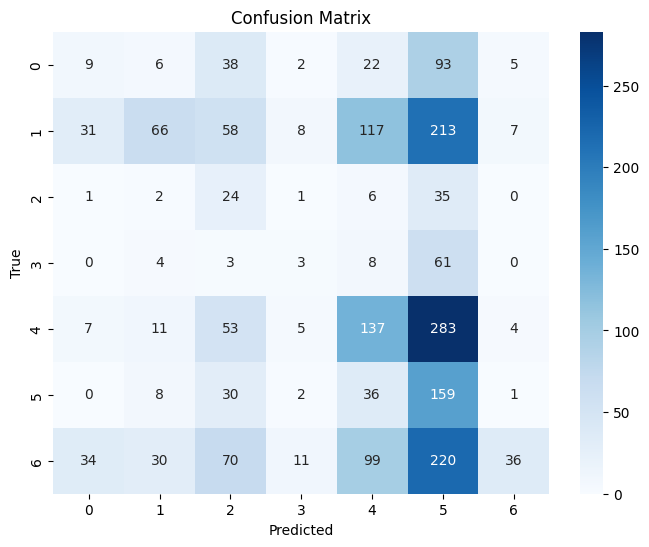

Macro ROC-AUC: 0.6066


In [7]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# -------------------------------
# Evaluation (Accuracy, Precision, Recall, F1, ROC-AUC, Confusion Matrix)
# -------------------------------
y_true = []
y_pred = []
y_probs = []

for images, labels in val_ds:
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
    y_probs.extend(preds)  # keep probabilities for ROC-AUC

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

# 1. Classification Report (Accuracy, Precision, Recall, F1)
print("Classification Report (on Target Domain):")
print(classification_report(y_true, y_pred, digits=4))

# 2. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# 3. ROC-AUC (macro-average across all classes)
y_true_onehot = tf.keras.utils.to_categorical(y_true, num_classes=NUM_CLASSES)
roc_auc = roc_auc_score(y_true_onehot, y_probs, multi_class="ovr", average="macro")
print(f"Macro ROC-AUC: {roc_auc:.4f}")
